# VK-LSVD: персональные Top-10 рекомендации

Сравнение ItemKNN, implicit ALS, EASE, FM с метапризнаками и Custom iALS.
FM с WNS — дополнительный режим обучения FM, Random — базовый ориентир.

Разделы 1–3 описывают данные и протокол, раздел 4 — модели и подбор параметров,
раздел 5 — повторное обучение, разделы 6–8 — результаты и выводы.

При `REPRODUCE=False` таблицы и графики строятся из сохранённых результатов.
При `REPRODUCE=True` выполняются обучение и оценка десяти выбранных конфигураций
(26 запусков с учётом seeds). Текстовые выводы относятся к исходному эксперименту;
новые значения отображаются в таблицах. Настройки выбирались по validation.


## 1. Данные и воспроизводимая выборка

**Источник:** [deepvk/VK-LSVD](https://huggingface.co/datasets/deepvk/VK-LSVD), официальный срез `up0.001_ip0.001`, зафиксированный revision `084a18386e149a454dd6dbe0123478e75c6b09ce`. Лицензия источника — Apache-2.0 (указана в исходном репозитории).

**Что рекомендуем:** короткие видео VK Clips (`item_id`) пользователям (`user_id`). Каждая запись — наблюдавшееся взаимодействие; это **не** рейтинг по шкале 1–5. Время `timespent` и реакции помогают вывести релевантность. Поля `age`, `gender`, `geo` пользователя и `author_id`, `duration` видео используются FM. `week` — номер исходного недельного файла; точного timestamp для каждого события нет.

**Исходный и итоговый объём:** в 25 недельных файлах опубликованного среза находилось **47 068 641** взаимодействие; после независимого выбора фиксированных ID осталось **1 454 216** (около **3.09%**). Отбор, проведённый до обучения: по 25 историческим неделям исходного среза независимо выбирались **3000 пользователей (`seed=42`) и 2000 видео (`seed=43`)**, затем сохранялись **все** взаимодействия выбранных пар. Не фильтровали события по лайкам, времени просмотра или будущей релевантности. Валидация и test не участвовали в отборе каталога. Размер после отбора — **1 454 216** пар, что соответствует диапазону 100k–2M. Исходный срез VK-LSVD уже подвергался отбору; результаты не относятся ко всей VK-аудитории.

**Воспроизведение подготовки:** из корня проекта, после установки зависимостей, выполните `python -m models.prepare_data`. Программа скачивает выбранные Parquet из HF, сохраняет `data/work/{interactions,users_metadata,items_metadata}.parquet` и `manifest.json`. Данные и большие кэши не следует помещать в GitHub.

Воспроизведение требует также недели 25 и 26. Код загрузки строго заданной ревизии приведён в §5; никакие параметры выборки по будущим неделям не меняются.

In [1]:
from pathlib import Path
from io import StringIO
import json, hashlib, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 16)
DATASET_URL = 'https://huggingface.co/datasets/deepvk/VK-LSVD'
SOURCE_REVISION = '084a18386e149a454dd6dbe0123478e75c6b09ce'
TOP_K = 10
SEEDS = (42,43,44)
RANDOM_SEEDS = (42,43,44,45,46)
ROOT = Path.cwd()  # для обучения запускать из корня репозитория
# Отчёт воспроизводим без сырых файлов. Ниже есть opt-in обучение из models/.
REPRODUCE = False
print('VK-LSVD | sampled 3000 users × 2000 items | train weeks 00–24, val 25, test 26')
print('Режим:', 'повторное обучение' if REPRODUCE else 'архивный отчёт')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

VK-LSVD | sampled 3000 users × 2000 items | train weeks 00–24, val 25, test 26
Режим: архивный отчёт


### 1.1. Фактический объём и проверка целостности

EDA выполнялось **только по train 0–24**. Ниже приведены результаты проверки данных перед обучением. В рабочей истории нет дубликатов `(user_id, item_id)`, нет пропусков обязательных полей и нулевых длительностей. Идентификаторы некоторых видео/пользователей требуют сохранения точных целочисленных типов (`uint64`): приведение к float опасно из-за потери точности.

In [2]:
DATA_CHECKS = pd.DataFrame([
    ('Исходный срез 00–24',47068641),('Взаимодействия train', 1454216), ('Пользователи',3000), ('Видео',2000),
    ('Разреженность 1 − плотность',1-1454216/(3000*2000)),
    ('Дубли пар user–item',0), ('Пропуски ключевых полей',0),
    ('Watch ratio > 1',172291), ('timespent == 255',562),
], columns=['Проверка','Значение'])
display(DATA_CHECKS)

,Проверка,Значение
0,Исходный срез 00–24,4.706864e+07
1,Взаимодействия train,1.454216e+06
2,Пользователи,3.000000e+03
3,Видео,2.000000e+03
4,Разреженность 1 − плотность,7.576307e-01
5,Дубли пар user–item,0.000000e+00
6,Пропуски ключевых полей,0.000000e+00
7,Watch ratio > 1,1.722910e+05
8,timespent == 255,5.620000e+02


**Вывод по качеству данных.** Рабочая матрица имеет плотность **24.24%** (достаточно плотная для учебной implicit-feedback задачи) и **75.76%** неизвестных пар. Значения `timespent=255` (562 события) и `timespent/duration>1` (172 291 событий, 11.85%) оставлены: они могут отражать особенности регистрации времени, а не обязательно ошибку. Обучающий target учитывает насыщение времени, чтобы такие наблюдения не доминировали.

## 2. EDA и определение интереса пользователя
### 2.1. Активность пользователей и популярность видео

EDA показываем компактно: только закономерности, необходимые для выбора моделей и target. Графики построены по сохранённым агрегатам train.

Медианы: событий/пользователь ≈ 488.0 | событий/видео ≈ 618.0


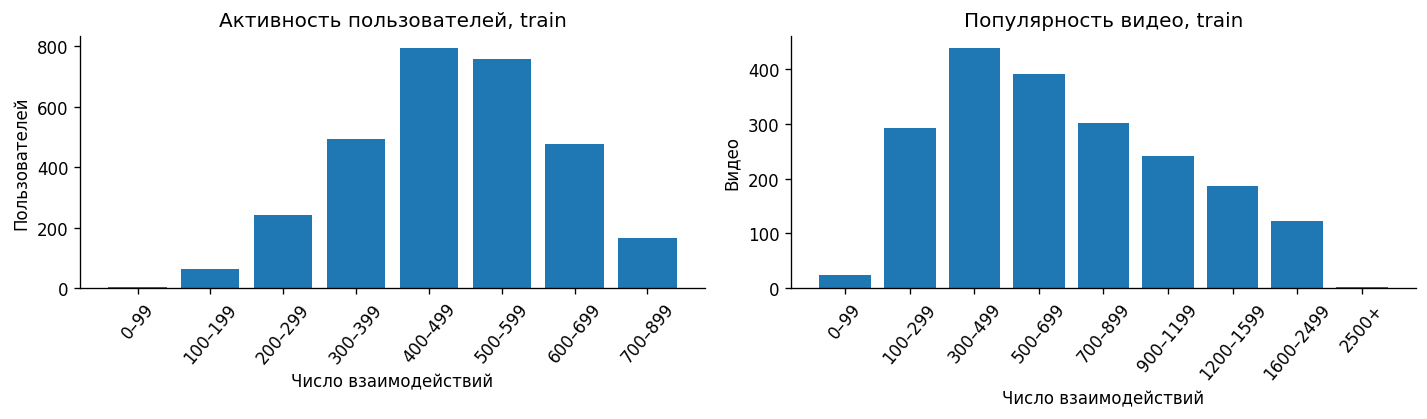

In [3]:
USER_HIST = pd.DataFrame({'bin':['0–99','100–199','200–299','300–399','400–499','500–599','600–699','700–899'], 'count':[3, 64, 241, 495, 795, 758, 477, 167]})
ITEM_HIST = pd.DataFrame({'bin':['0–99','100–299','300–499','500–699','700–899','900–1199','1200–1599','1600–2499','2500+'], 'count':[23, 293, 439, 392, 301, 241, 186, 123, 2]})
assert USER_HIST['count'].sum()==3000 and ITEM_HIST['count'].sum()==2000
fig,axes=plt.subplots(1,2,figsize=(12,3.6))
axes[0].bar(USER_HIST['bin'],USER_HIST['count']);axes[0].tick_params(axis='x',rotation=50)
axes[0].set_title('Активность пользователей, train');axes[0].set_ylabel('Пользователей');axes[0].set_xlabel('Число взаимодействий')
axes[1].bar(ITEM_HIST['bin'],ITEM_HIST['count']);axes[1].tick_params(axis='x',rotation=50)
axes[1].set_title('Популярность видео, train');axes[1].set_ylabel('Видео');axes[1].set_xlabel('Число взаимодействий')
plt.tight_layout();plt.show()
print('Медианы: событий/пользователь ≈', 488.0,
      '| событий/видео ≈',618.0)

**Вывод.** Активность пользователей и частота взаимодействий с видео неоднородны. Popularity неперсонализирована по определению; её качество нужно проверять экспериментально, а не выводить из формы распределения. На validation исторический positive-popularity baseline дал NDCG около 0.001866. Он не входил в финальный набор test-конфигураций. Для остальных моделей сохраняем фиксированный каталог; отсутствие взаимодействия не считаем доказательством отрицательного предпочтения.

### 2.2. Доля просмотра и явные реакции

Лайки — относительно редкие события (**13 621, 0.94%**) на фоне **1.45 млн** просмотров. Избранное ещё реже (**585, 0.04%**). Поэтому задавать позитивность **только** лайком означало бы потерять большую часть информации. Глубина просмотра коррелирует с лайками и даёт плотный implicit-сигнал.

In [4]:
RATIO_EDA = pd.read_csv(StringIO('ratio_bin,n,like_rate,like_count\n0,0,,0\n"(0, .1]",494499,0.0008877672149,439\n"(.1, .2]",199623,0.001933644921,386\n"(.2, .3]",100492,0.003900808025,392\n"(.3, .4]",80100,0.005780274657,463\n"(.4, .5]",59379,0.00756159585,449\n"(.5, .6]",48342,0.009639650821,466\n"(.6, .7]",44445,0.01133985825,504\n"(.7, .8]",51519,0.0135289893,697\n"(.8, .9]",46744,0.01814136574,848\n"(.9, 1]",156782,0.02141189677,3357\n"(1, 1.25]",102976,0.03021092293,3111\n"(1.25, 1.5]",20819,0.02963638984,617\n"(1.5, 2]",26679,0.03339705386,891\n"(2, 3]",14606,0.04231137889,618\n>3,7211,0.05311329913,383'))

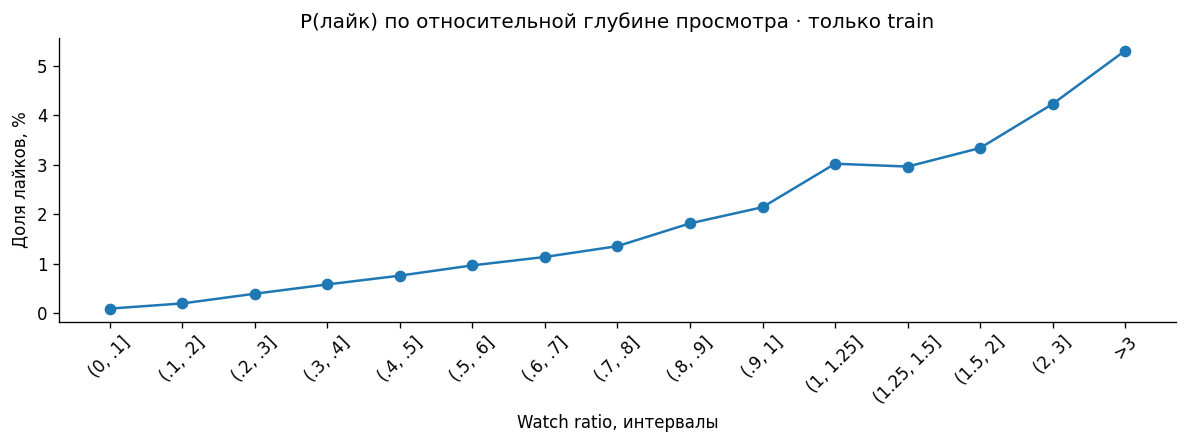

In [5]:
r=RATIO_EDA.loc[RATIO_EDA.n>=500].copy()
fig,ax=plt.subplots(figsize=(10,3.8))
ax.plot(r['ratio_bin'],100*r.like_rate,marker='o')
ax.set_title('P(лайк) по относительной глубине просмотра · только train')
ax.set_ylabel('Доля лайков, %');ax.set_xlabel('Watch ratio, интервалы');ax.tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()

**Вывод.** Чем глубже просмотр, тем выше условная доля лайков. Однако лайк не используем как единственный бинарный target, а `open_comments` не считаем однозначно положительным действием: оно может обозначать интерес, спор или негативную реакцию.

### 2.3. Длительность видео и абсолютное время просмотра

Короткие ролики легче набирают большой `watch_ratio`; поэтому **одной доли просмотра недостаточно** для оценки затрат внимания. В EDA при одинаковой глубине 75–100% доля лайков повышалась с примерно 0.95% для роликов 1–15 секунд до примерно 3.54% для 61–120 секунд. Это корреляция, не причинный эффект длительности.

In [6]:
DURATION_EDA = pd.read_csv(StringIO('duration_group,n,median_ratio,like_rate\n1–15с,336220,0.6363636364,0.007843078936\n16–30с,263377,0.25,0.008292295834\n31–60с,544759,0.1666666667,0.01057898998\n61–120с,252491,0.08080808081,0.01013105418\n121–180с,57369,0.03305785124,0.008349457024\n>180с,0,,'))

In [7]:
DURATION_LIKES = pd.read_csv(StringIO('duration_group,like_rate\n1–15с,0.009494375766\n16–30с,0.01696942844\n31–60с,0.02424719707\n61–120с,0.03540172774\n121–180с,0.03573859769\n>180с,'))

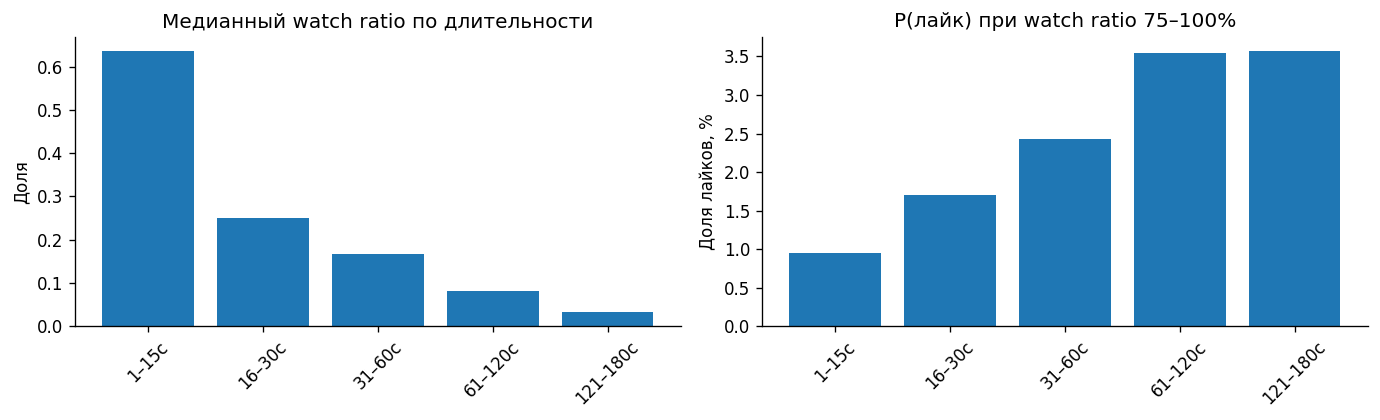

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11.6,3.6))
axes[0].bar(DURATION_EDA.duration_group,DURATION_EDA.median_ratio)
axes[0].set_title('Медианный watch ratio по длительности');axes[0].set_ylabel('Доля');axes[0].tick_params(axis='x',rotation=45)
axes[1].bar(DURATION_LIKES.duration_group,100*DURATION_LIKES.like_rate)
axes[1].set_title('P(лайк) при watch ratio 75–100%');axes[1].set_ylabel('Доля лайков, %');axes[1].tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()

**Вывод.** Это главное наблюдение, которое позднее мотивировало Custom iALS: даже внутри «положительного просмотра» сила интереса может различаться. Важно учитывать абсолютные секунды, но с насыщением, чтобы чрезмерно длинные просмотры не доминировали.

### 2.4. Неоднородность пользователей, метаданные и время

Возраст, код пола и анонимизированная география доступны в пользовательских метаданных; автор и длительность — в метаданных видео. Используем опубликованный snapshot metadata, без агрегирования будущих реакций. Доступность snapshot на момент рекомендации — **допущение**: особенно для `geo` (наиболее частая география) период исходного расчёта не подтверждён. Поэтому полное отсутствие временной утечки в исходных metadata не доказано.

Уровень активности существенно меняет привычку ставить лайки: у Q1 (малоактивные) ~3.0%, у Q4 (активные) ~0.165%. Это ещё одна причина не полагаться на явные реакции как на единственный сигнал. Историческая смесь длин роликов и активность по неделям неоднородны, что поддерживает **временное**, а не случайное разделение данных.

In [9]:
ACTIVITY_EDA = pd.read_csv(StringIO('activity_group,n_users,activity_median,like_rate\nQ1 (низкая),750,314,0.03005301656\nQ2,750,445,0.01195864128\nQ3,750,535,0.005043935067\nQ4 (высокая),750,644.5,0.001649473686'))

In [10]:
WEEKLY_EDA = pd.read_csv(StringIO('week,n_events,median_watch_ratio\n0,18329,0.2307692308\n1,29889,0.2068965517\n2,36482,0.1923076923\n3,42370,0.1851851852\n4,42990,0.1818181818\n5,28855,0.2\n6,42447,0.2474226804\n7,58498,0.2840909091\n8,69953,0.2962962963\n9,84010,0.6\n10,79052,0.4\n11,65052,0.2666666667\n12,61096,0.2203389831\n13,79790,0.25\n14,77362,0.2\n15,72109,0.2\n16,81782,0.2\n17,75317,0.2372881356\n18,112420,0.1764705882\n19,30951,0.1666666667\n20,47708,0.2380952381\n21,56402,0.1882352941\n22,56973,0.2\n23,61617,0.2060606061\n24,42762,0.2264150943'))

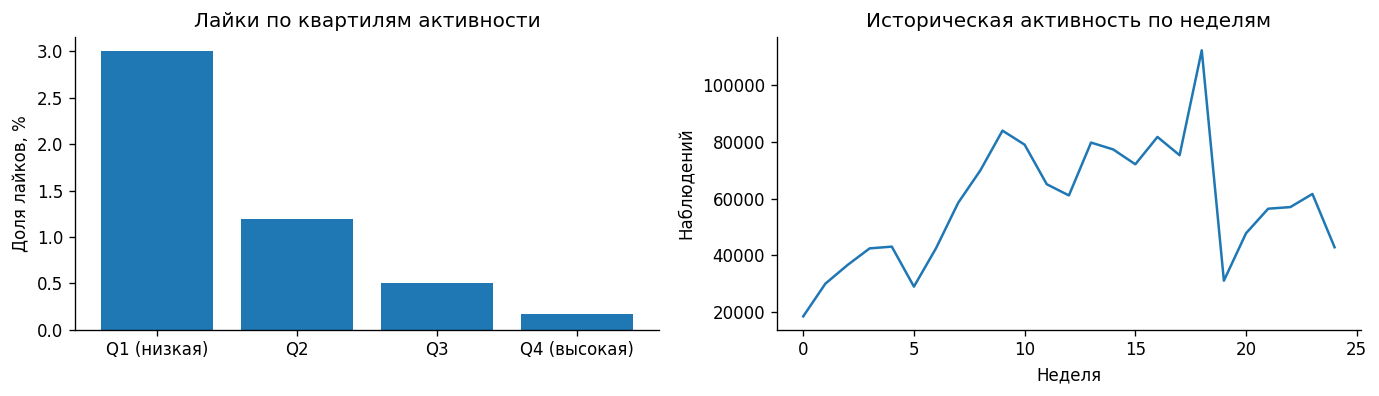

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11.6,3.4))
axes[0].bar(ACTIVITY_EDA.activity_group,100*ACTIVITY_EDA.like_rate)
axes[0].set_title('Лайки по квартилям активности');axes[0].set_ylabel('Доля лайков, %')
axes[1].plot(WEEKLY_EDA.week,WEEKLY_EDA.n_events)
axes[1].set_title('Историческая активность по неделям');axes[1].set_xlabel('Неделя');axes[1].set_ylabel('Наблюдений')
plt.tight_layout();plt.show()

**Проверка метаданных.** На фиксированных 3000 пользователях: медианный возраст — **33 года** (10–90-й перцентили: 21–50), категории `gender=1/2` — **1385/1615**; представлено **78** кодов `geo`. Среди 2000 видео — **1133** автора. Данные анонимизированы: из кодов пола или географии не следует восстанавливать семантику. В сохранённом EDA нет пропусков в обязательных полях (`age`, `gender`, `geo`, `author_id`, `duration`). Именно эти статические признаки используем для FM.

In [12]:
META_AUDIT=pd.DataFrame({'Признак':['age','gender','geo','author_id','duration'],
 'Источник':['user','user','user','item','item'],
 'Пропусков по train-only EDA':[0,0,0,0,0],
 'Используется в FM':[True]*5})
display(META_AUDIT)

,Признак,Источник,Пропусков по train-only EDA,Используется в FM
0,age,user,0,True
1,gender,user,0,True
2,geo,user,0,True
3,author_id,item,0,True
4,duration,item,0,True


### 2.5. Таргет релевантности 0 / 1 / 2

Пусть $t$ — `timespent` в секундах, $d$ — `duration` видео, $r=t/d$.

- **0:** дизлайк (приоритетный запрет) либо нет условий положительного интереса.
- **2:** $(r\ge 0.8\ \land\ t\ge 5)$ **или** $((like\lor bookmark)\land t\ge 3)$ при отсутствии дизлайка.
- **1:** $(r\ge 0.5\land t\ge 5)$ **или** $(r\ge 0.25\land t\ge 30)$, если более высокий уровень не назначен.

Дизлайк проверяется раньше всех остальных правил; `open_comments` не используется. Это **единое определение релевантности** для всех моделей при оценке. Обучающие сигналы моделей могут отличаться (binary или continuous), но не метки evaluator.

Обоснование: на train получено **922 110** событий `rel=0`, **148 820** `rel=1`, **383 286** `rel=2`. Наличие отдельного условия по абсолютным секундам уменьшает перекос в пользу коротких видео.

Пороги — эвристическая операционализация интереса, а не истинные оценки всех видео. Они создают скачки около 3/5/30 секунд и 0.25/0.5/0.8 доли просмотра; минимальное время может занижать интерес к очень коротким роликам. Быстрый лайк не обязательно ошибочный. `rel=0` объединяет явный dislike и отсутствие достаточных признаков позитивности. Пороговые правила после открытия test не менялись.

In [13]:
TRAIN_REL_COUNTS = pd.DataFrame({'rel':[0,1,2],'n':[922110,148820,383286]})
TRAIN_REL_COUNTS['share_pct'] = (100*TRAIN_REL_COUNTS.n/TRAIN_REL_COUNTS.n.sum()).round(2)
display(TRAIN_REL_COUNTS)

,rel,n,share_pct
0,0,922110,63.41
1,1,148820,10.23
2,2,383286,26.36


Агрегаты EDA рассчитаны на train 00–24. Их можно пересчитать скриптами `models.experiments.eda`, `eda_followup` и `eda_checks` после подготовки данных; команды приведены в §8.

## 3. Протокол сравнения

### 3.1. Строгое временное разбиение

| Период | События после фиксации каталога | Назначение |
|---|---:|---|
| **Train: week 00–24** | 1 454 216 | EDA, fit при подборе гиперпараметров |
| **Validation: week 25** | 16 158 | Выбор конфигураций и ранняя диагностика |
| **Test: week 26** | 13 454 | Финальная оценка feedback после заморозки конфигураций |

На финальной стадии модели переобучены **с нуля на train + validation (недели 00–25, 1 470 374 пар)**. Обучение на test **не производилось**. Вся обработка признаков и обучение модели FM происходят без использования будущих взаимодействий.

В исходном файле validation 519 839 событий, test — 387 800; после фильтрации на заранее зафиксированные 3000 пользователей и 2000 видео остаются числа выше. Это сильно ограничивает интерпретацию результатов: только выбранная учебная популяция.

До финального теста проводилась структурная проверка `user_id/item_id` недели 26: размеры и пересечения пар. Это не было чтением реакций или расчётом test-метрик. Состав каталога при этом не менялся.

In [14]:
SPLIT_COUNTS = pd.DataFrame({'period':['train 00–24','validation 25','test 26'],
 'events':[1454216,16158,13454], 'role':['EDA / tune fit','hyperparameter selection','one final evaluation']})
display(SPLIT_COUNTS)
print('После финального refit:', 1454216+16158, 'обучающих пар')

После финального refit: 1470374 обучающих пар


,period,events,role
0,train 00–24,1454216,EDA / tune fit
1,validation 25,16158,hyperparameter selection
2,test 26,13454,one final evaluation


### 3.2. Кандидаты и метрики

Для каждого пользователя модель формирует **score на все 2000 видео**, исключаем из рекомендаций **все** видео, просмотренные в разрешённой истории, включая события `rel=0`, затем берём Top-10. Отложенная неделя **не участвует в маскировании** — она используется только после формирования списка, чтобы оценить его. При равных score применяется фиксированное разрешение равенств по `item_id`.

- **Основная:** $\operatorname{NDCG}@10$ с **линейными gains $g(0)=0,g(1)=1,g(2)=2$**. $DCG@10=\sum_{j=1}^{10} g(rel_j)/\log_2(j+1)$; $IDCG$ — перестановка **известных положительных** объектов отложенной недели, а не неизвестной «истинной» релевантности всего каталога.
- **Дополнительные:** $\operatorname{Recall}@10$ (сколько известных релевантных объектов попало в Top-10) и $\operatorname{MAP}@10$ (качество их рангов).
- **Primary aggregation:** macro по **eligible** — пользователям хотя бы с одним положительным событием в holdout (2082 на validation, 1817 на test). All-users показатели приводятся отдельно. При $IDCG=0$ индивидуальный NDCG неопределён, такие пользователи не входят в primary mean.
- **Cold start:** новых пользователей/объектов не добавляем: фиксированный каталог уже определён до split. Неизвестные пары не становятся «реальными дизлайками»; в iALS они участвуют с предпочтением 0 и базовым confidence=1. Для FM применяется WNS.

Полные формулы дополнительных метрик для $R_u=\{i:rel_{ui}\ge1\}$:

$$Recall@10_u=\frac{\sum_{j=1}^{10}\mathbf1[\hat i_{uj}\in R_u]}{|R_u|},\quad
AP@10_u=\frac{\sum_{j=1}^{10} Precision@j_u\,\mathbf1[\hat i_{uj}\in R_u]}{\min(|R_u|,10)}.$$

MAP — среднее AP. При $|R_u|=0$ персональные метрики неопределены (NaN); в eligible-среднее пользователь не входит, для дополнительного all-users среднего его вклад принят равным нулю. Это условная оценка другой популяции, а не фильтрация обучающих данных. NDCG не является процентом правильных рекомендаций или CTR.

In [15]:
# Иллюстрация NDCG@10 без привлечения holdout при выборе рекомендаций.
def ndcg_linear_at_10(predicted_gains, ideal_gains):
    p=np.asarray(predicted_gains,dtype=float)[:10]
    ideal=np.sort(np.asarray(ideal_gains,dtype=float))[::-1][:10]
    discount=np.log2(np.arange(2,12))
    dcg=(p/discount[:len(p)]).sum()
    idcg=(ideal/discount[:len(ideal)]).sum()
    return float(dcg/idcg) if idcg>0 else np.nan
print('Пример: rel=2 на позиции 2, rel=1 на позиции 4 → NDCG =',
      round(ndcg_linear_at_10([0,2,0,1,0,0,0,0,0,0],[2,1]),3))

Пример: rel=2 на позиции 2, rel=1 на позиции 4 → NDCG = 0.643


## 4. Validation → фиксированные конфигурации пяти методов

Основная метрика выбрана до подбора: eligible macro NDCG@10. Сетки параметров использовали неделю 25. Итоговое обучение использует недели 00–25, затем выполняется оценка недели 26.

До test зафиксированы десять конфигураций: KNN80/640, iALS f10/12, EASE100, FM без WNS, WNS25/75, Custom-Time, Random. Validation-best обычной iALS — f12/10 итераций; длительный вариант FM — WNS75.

Код §5 повторяет финальные конфигурации. Подбор параметров на validation выполняется отдельными скриптами; команды приведены в §8. Все десять конфигураций показаны в итоговой таблице.

### 4.1. ItemKNN — item-based collaborative filtering

$X_{ui}=\mathbf1[rel_{ui}\ge1]$, сходство $s_{ij}$ — cosine между столбцами $X$, диагональ нулевая. Для каждого кандидата $i$ **глобально** выбирается его множество $N_K(i)$ ближайших видео:

$$\hat y_{ui}=\frac{\sum_{j\in N_K(i)}s_{ij}X_{uj}}{\sum_{j\in N_K(i)}s_{ij}}.$$

Знаменатель включает всех выбранных соседей кандидата, независимо от истории пользователя; ненаблюдаемые/неположительные соседи дают ноль в числителе. При нулевом знаменателе score равен нулю. Это нормировка по полной массе сходства, а не среднее только по понравившимся соседям. Рекомендации затем формирует общий evaluator с seen-mask.

Сетка $K\in\{5,10,20,40,80,160,320,640,1000,1500,1999\}$ × binary/graded × sum/normalized: 44 оценки. Binary normalized K640: val NDCG 0.018522, K80: 0.018183. Оба варианта зафиксированы до test.

In [16]:
ITEMKNN_PARAMS = {'signal':'binary','k':640,'aggregation':'normalized','metric':'cosine'}
print('ItemKNN:', ITEMKNN_PARAMS)

ItemKNN: {'signal': 'binary', 'k': 640, 'aggregation': 'normalized', 'metric': 'cosine'}


### 4.2. iALS — implicit matrix factorization

Минимизируем взвешенную ошибку для **всех** пар пользователь–видео:

$$\mathcal L=\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2 +\lambda(\|X\|_F^2+\|Y\|_F^2).$$

Для позитивных наблюдений $p=1$, $c=1+\alpha$; для остальных пар $p=0$, $c=1$. Решаем попеременно задачи на пользовательские и объектные факторы, без сторонней ALS-реализации. В исследованной low-rank сетке $f\in\{2,4,6,8,10,12,14,16\}$, пары $(\alpha,\lambda)=(40,10)$ для binary и $(10,1)$ для graded, checkpoints после 5/10/15 итераций; ранее изучались и более высокие размерности. В финальном отчёте используем бинарный confidence. На validation **f=12, $\alpha=40$, $\lambda=10$, 10 итераций** дала NDCG **0.020702**, а более дешёвая **f=10, 5 итераций** — **0.020499** (разница около 1%). В компактном отчёте оставляем последнюю, сохраняя f12 в контрольном сравнении для Custom.

In [17]:
IALS_PARAMS={'factors':10,'alpha':40.0,'regularization':10.0,'confidence_mode':'binary',
             'n_iters':5,'seeds':SEEDS}
print('iALS:', IALS_PARAMS)

iALS: {'factors': 10, 'alpha': 40.0, 'regularization': 10.0, 'confidence_mode': 'binary', 'n_iters': 5, 'seeds': (42, 43, 44)}


### 4.3. EASE — аналитическое item–item восстановление

Решаем $\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2$, $\operatorname{diag}(B)=0$. При $P=(X^\top X+\lambda I)^{-1}$ коэффициенты $B_{ij}=-P_{ij}/P_{jj}$ для $i\neq j$, $B_{ii}=0$. В отличие от SLIM, L1-штраф отсутствует.

Исследовали `binary` и `graded` при $\lambda\in\{1,3,10,30,100,300,1000,3000,10000\}$; победил **binary, $\lambda=100$**, validation NDCG@10 **0.014335**. Для этого метода не нужны метапризнаки и стохастические seeds.

Коэффициенты EASE могут быть отрицательными: ограничение неотрицательности стандартной EASE здесь не накладывается. Нулевая диагональ исключает тривиальное самовосстановление объекта.

In [18]:
EASE_PARAMS={'signal':'binary','regularization':100.0}
print('EASE:', EASE_PARAMS)

EASE: {'signal': 'binary', 'regularization': 100.0}


### 4.4. Factorization Machines — метаданные + WNS

FM второго порядка учитывает взаимодействия разреженных признаков (ID пользователей и видео, `author_id`, `duration`, `age`, `gender`, `geo`):

$$\widehat y(x)=w_0+\sum_j w_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$

Оптимизация через PyTorch AdamW и **binary cross-entropy**. Для исходной FM основная сетка включала факторы $f\in\{4,8,16,32,64\}$, learning rate $\{0.0003,0.001,0.003\}$, weight decay $\{0,0.01,0.1\}$ и checkpoints 5/10/15 эпох (всего 135 основных комбинаций). В исходной постановке обучение только на наблюдавшихся парах почти не различало непросмотренный каталог: validation NDCG **0.000733**. Сохранили **ту же архитектуру и признаки**, но добавили **равномерные неизвестные user–item пары** в пропорции 1:1, pseudo-label 0, weighted BCE с $\beta=20$ (*Weighted Negative Sampling*). Получили validation **0.019822** на 25-й эпохе.

Финальные две конфигурации **одного метода**: Full FM без WNS (15 эпох) и Full FM с WNS ($\beta=20$, 25 эпох). Для обеих: 64 фактора, lr=0.003, AdamW weight_decay=0.1, batch=8192, seeds 42–44. В признаки не входят watch time, likes и test-target. Кодировщик использует исторические данные и опубликованный snapshot metadata; временная доступность самого snapshot остаётся указанным выше допущением.

WNS выбирает равномерно неизвестные **пары** из дополнения исторических взаимодействий, включая исключение наблюдённых `rel=0`. Это не равное число негативов для каждого пользователя и не автоматически несмещённая оценка полного catalog-loss. Сравнение 15 эпох без WNS с 25 эпохами WNS меняет и обучающие пары, и бюджет оптимизации. Также до test зафиксирован WNS75.

При равном числе наблюдаемых и sampled-пар WNS минимизирует $[\overline{BCE}_{obs}+\beta\,\overline{BCE}_{unknown}]/(1+\beta)$ с AdamW; sampled-метки равны нулю. Скоринг использует логит FM: сигмоида монотонна и не меняет порядок Top-10.

In [19]:
FM_PARAMS={'n_factors':64,'learning_rate':0.003,'weight_decay':0.1,'batch_size':8192,
           'feature_set':'full','seeds':SEEDS}
FM_WNS={'negative_weight':20.,'negative_ratio':1.,'sampling_strategy':'uniform_unobserved',
        'max_catalog_pairs':10_000_000,'epochs':25,'sampling_seed_rule':'seed+1000'}
print('FM shared:', FM_PARAMS); print('FM WNS:',FM_WNS)

FM shared: {'n_factors': 64, 'learning_rate': 0.003, 'weight_decay': 0.1, 'batch_size': 8192, 'feature_set': 'full', 'seeds': (42, 43, 44)}
FM WNS: {'negative_weight': 20.0, 'negative_ratio': 1.0, 'sampling_strategy': 'uniform_unobserved', 'max_catalog_pairs': 10000000, 'epochs': 25, 'sampling_seed_rule': 'seed+1000'}


#### Влияние метаданных: отдельная validation-абляция

При β=5, seed42 и 25 эпохах Full не превосходит ID-only: ΔNDCG = −0.000281, paired 95% CI [−0.003040; +0.002637]. Добавочная польза metadata **не доказана в этой проверке**. Это не доказательство их общей бесполезности: один seed и β=5 не полностью совпадают с финальным β=20. Требование задания использовать FM с metadata выполнено независимо от знака эффекта.

In [20]:
METADATA_ABLATION=pd.read_csv(StringIO('feature_set,negative_weight,seed,epoch,eligible_ndcg_at_10\nfull,5.0,42,25,0.0176347836136658\nid,5.0,42,25,0.0179157014769226\nitem_meta,5.0,42,25,0.0161186873094077\nuser_meta,5.0,42,25,0.0152500725163756\n'))
display(METADATA_ABLATION.round(6))

,feature_set,negative_weight,seed,epoch,eligible_ndcg_at_10
0,full,5.0,42,25,0.017635
1,id,5.0,42,25,0.017916
2,item_meta,5.0,42,25,0.016119
3,user_meta,5.0,42,25,0.015250


### 4.5. Custom iALS — непрерывный обучающий target

Структура iALS остаётся прежней, **меняем именно target $q_{ui}$, а не только confidence**. По EDA наблюдения о лайках и длительности мотивировали зависимость от абсолютных секунд просмотра. После validation-экспериментов оставили **Time-only** среди уже положительных взаимодействий:

$$q_{ui}=\begin{cases}0,&rel_{ui}=0,\\ \min\left(1,\;0.4+0.6\frac{\ln(1+\min(t_{ui},60))}{\ln 61}+0.1\mathbb 1[like\lor bookmark]\right),&rel_{ui}>0.\end{cases}$$

Watch ratio всё ещё участвует в разметке `rel`; «Time-only» означает лишь отсутствие отдельного слагаемого $r$ **внутри непрерывного положительного target**. При $rel=0$ и для непросмотренных $q=0$; positive confidence $1+40$, unknown confidence 1. Проверили 24 комбинации $q_{min}\in\{0.4,0.7\},\; w\in\{0.3,0.6,0.8\},\;\delta\in\{0,0.2\},\;\tau\in\{30,60\}$ при фиксированном $\gamma=0.1$, затем адресную проверку $w=0$ и checkpoints 10/15 на seeds 42–44. Лучшая выбранная конфигурация — **f=12, $\alpha=40$, $\lambda=10$, 15 итераций**, validation NDCG по 3 seeds **0.027401**.

Важно: в validation **при тех же 15 итерациях** исходная binary iALS имела среднюю NDCG **0.018659**, Full continuous — **0.026918**, Time-only — **0.027401**. Таким образом, польза формы target поддерживается отдельной контролируемой проверкой, а не только сравнением конфигураций в test.

Контроль масштаба: при постоянном target положительных пар около 0.8834 val NDCG ≈0.020604, тогда как Full continuous ≈0.026986 (сопоставимая проверка seed42/10 итераций). Поэтому эффект не сводится к единому масштабированию. Time-only против Full при 15 итерациях: средняя ΔNDCG +0.000483, paired CI [−0.000872; +0.001976]; статистически убедительное превосходство Time-only не установлено. Это выбранный по validation более простой вариант. Название не означает отсутствия бонуса like/bookmark.

В исходной сетке положительный target имел вид $q=\min(1,q_{min}+(1-q_{min})[w f_r+(1-w)f_t]+\gamma e)$, где $f_r=(1-\delta)\min(r,1)+\delta\min(\max(r-1,0),1)$, $f_t=\ln(1+\min(t,\tau))/\ln(1+\tau)$, $e=\mathbf1[like\lor bookmark]$. Это определяет смысл перечисленных параметров поиска; окончательно выбран $w=0$.

In [21]:
CUSTOM_PARAMS={'factors':12,'alpha':40.0,'regularization':10.0,'confidence_mode':'binary',
               'n_iters':15,'q_min':0.4,'w':0.0,'delta':0.0,'tau':60.0,'gamma':0.1,
               'seeds':SEEDS}
from models.custom_ials import time_only_target
q_examples=time_only_target([10,30,60,3],[2,1,2,0],[0,0,1,1],[0,0,0,0])
display(pd.DataFrame({'seconds':[10,30,60,3],'rel':[2,1,2,0],'target':q_examples.round(3)}))

,seconds,rel,target
0,10,2,0.750
1,30,1,0.901
2,60,2,1.000
3,3,0,0.000


### 4.6. Итоговые параметры и результаты на validation

Ниже — данные из сохранённых результатов validation. **Random** оцениваем отдельно как беспараметрический baseline (равномерные независимые scores; 5 seeds).

In [22]:
# Архивные источники; точность CSV сохранена. Никаких новых измерений здесь нет.
ARCHIVE_SUMMARY = pd.read_csv(StringIO('model,n_seeds,seeds,n_eligible,mean_fit_seconds,unique_items_mean,ndcg_at_10,ndcg_at_10_seed_std,ndcg_at_10_ci_low,ndcg_at_10_ci_high,recall_at_10,recall_at_10_seed_std,recall_at_10_ci_low,recall_at_10_ci_high,map_at_10,map_at_10_seed_std,map_at_10_ci_low,map_at_10_ci_high,all_ndcg_at_10,all_recall_at_10,all_map_at_10,validation_ndcg_at_10\nCIALS-TIME,3,"42,43,44",1817,3.616147097999999,1493.3333333333333,0.0359202833492943,0.0016907561551384,0.0308864048127712,0.0410040259310332,0.0630814791519249,0.0015629594708298,0.0547619593608861,0.0711355386953901,0.0210882816303512,0.0016488612030876,0.0173109172275282,0.0248835911150574,0.0217557182818892,0.0382063492063492,0.0127724692407827,0.027401\nFM-WNS-25,3,"42,43,44",1817,55.51323426333327,1333.0,0.020699490768425,0.0011988969020239,0.0171987091737395,0.0243746435765702,0.0365708345345109,0.0026786372366802,0.0308909570983043,0.0425357950922067,0.0117273242283725,0.0009254729525009,0.0092630875361722,0.0145481080291632,0.0125369915754094,0.0221497354497354,0.0071028493743176,0.019822\nIALS-10,3,"42,43,44",1817,1.079854916333365,1701.3333333333333,0.0205625986418078,0.0023161268625648,0.0168199296340475,0.0245344874672782,0.0359267253873748,0.0052981900983286,0.0299224168328461,0.0421577021095458,0.0121823018736429,0.0011128007343369,0.009348146491979,0.0152494195824949,0.0124540805773882,0.02175962000962,0.0073784141681363,0.020499\nKNN-640,1,,1817,2.16567225,1866.0,0.0205524078042848,,0.0164587082993238,0.0247648743492613,0.0372801845008779,,0.0302680700788846,0.0449471591057997,0.0119349114622917,,0.0089852736537347,0.0151859482059502,0.0124479083267952,0.022579365079365,0.007228578042328,0.018522\nIALS-12,3,"42,43,44",1817,2.423087223333312,1767.0,0.0196795701248837,0.0006009662863859,0.0160676272461359,0.0234559365430005,0.033835207170375,0.0019390512216802,0.0280402132417817,0.0397139013374566,0.0114853212631798,0.0006706279872188,0.0088965122673338,0.014266147332422,0.0119192596389712,0.0204928571428571,0.0069562762450659,0.020702\nFM-WNS-75,3,"42,43,44",1817,166.8176045409999,1335.0,0.0183356630354113,0.0007658704910011,0.0152901455118498,0.021633640490968,0.0334342322509631,0.000764002889283,0.0281544015514846,0.0390099894296372,0.0098651126097924,0.0002230153996506,0.0078510591049746,0.0122030355638351,0.0111052999117807,0.02025,0.0059749698706643,0.020786\nKNN-80,1,,1817,2.16567225,1886.0,0.0146871694405932,,0.011265045680878,0.0182008113176767,0.0273868490709437,,0.021214783656996,0.0338552559163456,0.008283062231191,,0.0058830819232236,0.0109441390541418,0.0088955289578526,0.0165873015873015,0.005016774691358,0.018183\nEASE-100,1,,1817,2.2627283749999947,1083.0,0.0107089279403381,,0.0080864916426147,0.0135960847136673,0.0199707786251539,,0.0152500687947165,0.0252720503446287,0.005660227002805,,0.0039681801296315,0.0074624461706042,0.0064860406891981,0.0120956349206349,0.0034282108213655,0.014335\nRANDOM,5,"42,43,44,45,46",1817,0.0200676917999771,1999.4,0.0037742246785317,0.0004017335137287,0.0030160015075092,0.0046033012520611,0.006830157856575,0.0013833560514132,0.005462646652864,0.0082721682784285,0.0021281574330949,0.0001808154380714,0.0015915671691228,0.0027232906436897,0.0022859220802973,0.0041367989417989,0.0012889540186444,0.003595\nFM-0,3,"42,43,44",1817,12.90205604133329,630.0,0.0006464723860058,0.0002278607488911,9.75329233642986e-05,0.0015208198295575,0.001131290894637,0.000140114220478,0.0001834525775087,0.0025377606555372,0.0004392670050347,0.0002708184623452,4.578670580321667e-05,0.001109939052977,0.0003915467751242,0.0006851851851851,0.000266049382716,0.000733\n'))
ARCHIVE_RUNS = pd.read_csv(StringIO('model,seed,run,n_eligible,n_users,ndcg_at_10,recall_at_10,map_at_10,all_ndcg_at_10,all_recall_at_10,all_map_at_10,fit_seconds,unique_recommended_items,top100_share\nKNN-80,,knn_80,1817,3000,0.0146871694405932,0.0273868490709437,0.008283062231191,0.0088955289578526,0.0165873015873015,0.005016774691358,2.16567225,1886,0.2938666666666666\nKNN-640,,knn_640,1817,3000,0.0205524078042848,0.0372801845008779,0.0119349114622917,0.0124479083267952,0.022579365079365,0.007228578042328,2.16567225,1866,0.2437333333333333\nEASE-100,,ease_100,1817,3000,0.0107089279403381,0.0199707786251539,0.005660227002805,0.0064860406891981,0.0120956349206349,0.0034282108213655,2.2627283749999947,1083,0.5489333333333334\nIALS-10,42.0,ials_10_s42,1817,3000,0.0197031945328043,0.0349361608855279,0.0114262382320995,0.0119335681553685,0.0211596681096681,0.0069204916225749,1.1088782499999752,1697,0.2372333333333333\nIALS-10,43.0,ials_10_s43,1817,3000,0.0187990127360624,0.0311937283043502,0.0116605552206818,0.0113859353804751,0.0188930014430014,0.0070624096119929,1.0903548330000206,1701,0.2422\nIALS-10,44.0,ials_10_s44,1817,3000,0.0231855886565567,0.0416502869722462,0.0134601121681473,0.0140427381963212,0.0252261904761904,0.0081523412698412,1.0403316660000996,1706,0.2371\nIALS-12,42.0,ials_12_s42,1817,3000,0.0202280690914688,0.0360733286159813,0.011613133145388,0.0122514671797329,0.0218484126984126,0.0070336876417233,2.4855538759999263,1769,0.2200333333333333\nIALS-12,43.0,ials_12_s43,1817,3000,0.0190371873231944,0.0327711822208244,0.0107599850617186,0.0115301897887481,0.0198484126984127,0.0065169642857142,2.50298562699993,1775,0.2205333333333333\nIALS-12,44.0,ials_12_s44,1817,3000,0.0197734539599878,0.0326611106743192,0.0120828455824328,0.0119761219484326,0.019781746031746,0.0073181768077601,2.2807221670000786,1757,0.2209333333333333\nFM-0,42.0,fm_0_s42,1817,3000,0.0005122050402165,0.0011007154650522,0.0003210420106402,0.0003102255193577,0.0006666666666666,0.0001944444444444,13.092912541999963,633,0.9043333333333332\nFM-0,43.0,fm_0_s43,1817,3000,0.0009095645513835,0.0010089891762979,0.0007490980248272,0.0005508929299546,0.0006111111111111,0.0004537037037037,12.83003824999986,651,0.8904666666666666\nFM-0,44.0,fm_0_s44,1817,3000,0.0005176475664174,0.0012841680425609,0.0002476609796367,0.0003135218760601,0.0007777777777777,0.00015,12.78321733200005,606,0.9026333333333332\nFM-WNS-25,42.0,fm_wns_25_s42,1817,3000,0.019747103443307,0.0337801713971224,0.0117137361885376,0.0119601623188296,0.0204595238095238,0.0070946195515243,55.09870120599993,1330,0.4814333333333333\nFM-WNS-25,43.0,fm_wns_25_s43,1817,3000,0.0203055852591084,0.036811070052677,0.0108087201125175,0.0122984161386,0.022295238095238,0.0065464814814814,55.925536916000055,1335,0.4784666666666666\nFM-WNS-25,44.0,fm_wns_25_s44,1817,3000,0.0220457836028595,0.0391212621537332,0.0126595163840623,0.0133523962687986,0.0236944444444444,0.007667447089947,55.51546466799982,1334,0.4795666666666666\nFM-WNS-75,42.0,fm_wns_75_s42,1817,3000,0.0182383788530762,0.0334447152553921,0.0098121940637075,0.0110463781253464,0.0202563492063492,0.0059429188712522,165.948377871,1327,0.4843333333333333\nFM-WNS-75,43.0,fm_wns_75_s43,1817,3000,0.0191455274659034,0.034192939696517,0.0101098276710549,0.0115958078018488,0.0207095238095238,0.0061231856261022,167.98036074599986,1338,0.4485\nFM-WNS-75,44.0,fm_wns_75_s44,1817,3000,0.0176230827872542,0.0326650418009801,0.0096733160946149,0.0106737138081469,0.0197841269841269,0.0058588051146384,166.52407500599986,1340,0.4674\nCIALS-TIME,42.0,cials_time_s42,1817,3000,0.0377336858235241,0.064376130198915,0.022850995011837,0.0228540357137811,0.0389904761904761,0.0138400859788359,3.272074373999999,1488,0.2385333333333333\nCIALS-TIME,43.0,cials_time_s43,1817,3000,0.0343872156252235,0.0613452315433603,0.0195837280059703,0.020827190263677,0.0371547619047619,0.0118612112622826,3.690512334000005,1510,0.2399\nCIALS-TIME,44.0,cials_time_s44,1817,3000,0.0356399485991352,0.0635230757134995,0.0208301218732463,0.0215859288682095,0.0384738095238095,0.0126161104812295,3.8858545859999936,1482,0.2379333333333333\nRANDOM,42.0,random_s42,1817,3000,0.0035173576087905,0.0057702387504258,0.001944116850556,0.0021303462583907,0.0034948412698412,0.0011774867724867,0.0209344579999424,2000,0.0858\nRANDOM,43.0,random_s43,1817,3000,0.0036270626762509,0.00691310462912,0.0021859066197261,0.0021967909609159,0.004187037037037,0.0013239307760141,0.0201132089999873,1998,0.0839666666666666\nRANDOM,44.0,random_s44,1817,3000,0.0038179854110818,0.0072616645263865,0.0023383032966136,0.0023124264973118,0.0043981481481481,0.0014162323633156,0.0197087919999603,2000,0.0841\nRANDOM,45.0,random_s45,1817,3000,0.0044498940527952,0.0088620698692245,0.0022377127332312,0.0026951524979762,0.0053674603174603,0.0013553080120937,0.0196582500000204,2000,0.0850666666666666\nRANDOM,46.0,random_s46,1817,3000,0.0034588236437401,0.0053437115077181,0.0019347476653475,0.0020948941868919,0.0032365079365079,0.0011718121693121,0.0199237499999753,1999,0.0840666666666666\n'))
ARCHIVE_PAIRED = pd.read_csv(StringIO('model_a,model_b,estimate,ci_low,ci_high,ci,n_bootstrap,seed,n_users,method,metric,group,difference\nCIALS-TIME,IALS-12,0.0162407132244105,0.0133331439166367,0.0191250744342544,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nFM-WNS-75,FM-0,0.0176891906494054,0.0145527213901181,0.0210543115430124,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nFM-WNS-75,FM-WNS-25,-0.0023638277330137,-0.0047109921095317,0.0001073613757452,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nKNN-640,KNN-80,0.0058652383636916,0.0016238887506163,0.0101798997182459,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nIALS-12,IALS-10,-0.0008830285169241,-0.0028162338803649,0.001120484103043,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nCIALS-TIME,FM-WNS-75,0.017584620313883,0.0124501848805084,0.0222787178263088,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\nCIALS-TIME,RANDOM,0.0321460586707625,0.0269874787534719,0.037270344861946,0.95,2000,20261024,1817,percentile; linear quantiles; resampling users,ndcg_at_10,eligible,model_A - model_B\n'))
PARAMETERS = {'KNN-640': 'binary; normalized; K=640', 'KNN-80': 'binary; normalized; K=80', 'IALS-10': 'f=10; α=40; λ=10; iter=5', 'IALS-12': 'f=12; α=40; λ=10; iter=10', 'EASE-100': 'binary; λ=100', 'FM-0': 'full; f=64; lr=.003; wd=.1; ep=15', 'FM-WNS-25': 'full; f=64; β=20; ep=25', 'FM-WNS-75': 'full; f=64; β=20; ep=75', 'CIALS-TIME': 'time target; f=12; α=40; λ=10; iter=15', 'RANDOM': 'uniform; seeds=42–46'}
BOOTSTRAP_N=2000
BOOTSTRAP_SEED=20261024

In [23]:
validation_view=ARCHIVE_SUMMARY[['model','validation_ndcg_at_10']].copy()
validation_view['Параметры']=validation_view.model.map(PARAMETERS)
validation_view['Val aggregation']=validation_view.model.map({
 'CIALS-TIME':'mean seeds 42–44','FM-WNS-25':'mean seeds 42–44',
 'FM-WNS-75':'mean seeds 42–44','RANDOM':'mean seeds 42–46',
 'IALS-10':'seed 42','IALS-12':'seed 42','FM-0':'seed 42',
 'KNN-640':'deterministic','KNN-80':'deterministic','EASE-100':'deterministic'})
display(validation_view.sort_values('validation_ndcg_at_10',ascending=False).round(6))

,model,validation_ndcg_at_10,Параметры,Val aggregation
0,CIALS-TIME,0.027401,time target; f=12; α=40; λ=10; iter=15,mean seeds 42–44
5,FM-WNS-75,0.020786,full; f=64; β=20; ep=75,mean seeds 42–44
4,IALS-12,0.020702,f=12; α=40; λ=10; iter=10,seed 42
2,IALS-10,0.020499,f=10; α=40; λ=10; iter=5,seed 42
1,FM-WNS-25,0.019822,full; f=64; β=20; ep=25,mean seeds 42–44
3,KNN-640,0.018522,binary; normalized; K=640,deterministic
6,KNN-80,0.018183,binary; normalized; K=80,deterministic
7,EASE-100,0.014335,binary; λ=100,deterministic
8,RANDOM,0.003595,uniform; seeds=42–46,mean seeds 42–46
9,FM-0,0.000733,full; f=64; lr=.003; wd=.1; ep=15,seed 42


## 5. Повторение финального сравнения

Запускать из корня проекта. При `REPRODUCE=True` данные загружаются с фиксированной
ревизии, модели обучаются с выбранными на validation параметрами, результаты
сохраняются в отдельной папке `results/experiments_reproduction/`.

Проверяются контрольные суммы, состав выборки и разметка. SHA256 рабочих Parquet
зависит от сериализации: при смене pandas/PyArrow несовпадение требует проверки
эквивалентности данных. CPU и MPS могут давать численные различия.


In [24]:
# Утверждённые контрольные суммы исходных таблиц (SHA256 байтов).
EXPECTED_SOURCE_SHA={
 'interactions.parquet':'0c3a20a9729e30aeb650b28379d34663d3d2ec914bfe0ee3ca0a17d0904790a0',
 'users_metadata.parquet':'c0769c126e96499364f902362902690774005947d9fe23e097e43718d26d5cb2',
 'items_metadata.parquet':'3140e6749978a817e552a510c91f0c402eb93a639a096dc81c0bc99526b27d71',
 'week_26.parquet':'e76cae7fec551fb279ce5013620604efa5c89e16bef6be2dd5361ee64b85d838',
 'week_25.parquet':'d654b40a7f7e2086054c6131767967f84289fafd2364f566b984cc7d408917f5',
}
def file_sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1<<20),b''):h.update(block)
    return h.hexdigest()

if REPRODUCE:
    from huggingface_hub import hf_hub_download
    import subprocess, sys, tempfile, warnings
    if not (ROOT/'models').is_dir() or not (ROOT/'models/prepare_data.py').is_file():
        raise FileNotFoundError('Запустите notebook из корня полного проекта с models/.')
    source=ROOT/'data/source'; source.mkdir(parents=True,exist_ok=True)
    revision_path=source/'source_revision.json'
    revision_record={'repo':'deepvk/VK-LSVD','revision':SOURCE_REVISION}
    if revision_path.exists():
        assert json.loads(revision_path.read_text())==revision_record, 'Другая ревизия: используйте отдельную чистую копию проекта.'
    else:
        revision_path.write_text(json.dumps(revision_record,indent=2),encoding='utf-8')
    work_names=['interactions.parquet','users_metadata.parquet','items_metadata.parquet','manifest.json']
    present=[(ROOT/'data/work'/name).exists() for name in work_names]
    if any(present) and not all(present):
        raise FileNotFoundError('Неполный data/work: восстановите комплект; автоматическая перезапись отключена.')
    if not any(present):
        from models.utils.preparation import CONFIG
        cfg=CONFIG.copy()
        assert cfg['sample_users']==3000 and cfg['sample_items']==2000 and cfg['random_seed']==42 and cfg['history_weeks']==25
        assert cfg['dataset_repo']=='deepvk/VK-LSVD' and cfg['subsample']=='up0.001_ip0.001'
        subprocess.run([sys.executable,'-m','models.prepare_data'],cwd=ROOT,check=True)
    for split,week in [('validation',25),('test',26)]:
        rel=f'subsamples/up0.001_ip0.001/{split}/week_{week}.parquet'
        if not (source/rel).is_file():
            hf_hub_download(repo_id='deepvk/VK-LSVD',repo_type='dataset',filename=rel,
                            revision=SOURCE_REVISION,local_dir=str(source))
    from models.item_knn import ItemKNN
    from models.ials import IALS
    from models.custom_ials import CustomIALS
    from models.ease import EASE
    from models.fm import FactorizationMachine,prepare_fm_data
    from models.fm_wns import SampledFactorizationMachine
    from models.utils.evaluation import label_relevance,evaluate_scores
    import torch
    paths={'interactions.parquet':ROOT/'data/work/interactions.parquet',
           'users_metadata.parquet':ROOT/'data/work/users_metadata.parquet',
           'items_metadata.parquet':ROOT/'data/work/items_metadata.parquet',
           'week_25.parquet':ROOT/'data/source/subsamples/up0.001_ip0.001/validation/week_25.parquet'}
    for name,path in paths.items():
        assert path.exists() and file_sha256(path)==EXPECTED_SOURCE_SHA[name],f'Изменён source: {path}'
    rerun_parent=ROOT/'results/experiments_reproduction'
    rerun_parent.mkdir(parents=True,exist_ok=True)
    RERUN_DIR=Path(tempfile.mkdtemp(prefix='run_',dir=rerun_parent))
    RUN_ENV={'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,'torch':str(torch.__version__)}
    (RERUN_DIR/'environment.json').write_text(json.dumps(RUN_ENV,indent=2),encoding='utf-8')
    print('Источники train/metadata/val проверены; test-feedback ещё не прочитан.')
else:
    print('REPORT MODE. Обучение при чтении отчёта не повторяется.')

REPORT MODE. Обучение при чтении отчёта не повторяется.


In [25]:
if REPRODUCE:
    train=pd.read_parquet(paths['interactions.parquet'])
    val=pd.read_parquet(paths['week_25.parquet'])
    umeta=pd.read_parquet(paths['users_metadata.parquet'])[['user_id','age','gender','geo']]
    imeta=pd.read_parquet(paths['items_metadata.parquet'])[['item_id','author_id','duration']]
    U=np.sort(umeta.user_id.to_numpy(dtype=np.uint64));I=np.sort(imeta.item_id.to_numpy(dtype=np.uint64))
    assert len(U)==3000 and len(I)==2000 and len(train)==1454216
    assert not train.duplicated(['user_id','item_id']).any()
    assert set(train.week.unique())==set(range(25))
    assert not umeta.isna().any().any() and not imeta.isna().any().any()
    assert umeta.user_id.is_unique and imeta.item_id.is_unique
    assert train.user_id.isin(U).all() and train.item_id.isin(I).all()
    assert hashlib.sha256(U.tobytes()).hexdigest()=='ce51fd99e116ae5884714fcaf2244b6b99c4d5268ed961426ea86b8277c7780b'
    assert hashlib.sha256(I.tobytes()).hexdigest()=='e69b0688d7d2ff4a68375a9bc711026d58899b565ce93c4c4c94692c29b59e76'
    val=val.loc[val.user_id.isin(U)&val.item_id.isin(I)].copy()
    assert len(val)==16158 and not val.duplicated(['user_id','item_id']).any()
    val['week']=np.int16(25)
    for col in ('user_id','item_id'):
        assert train[col].dtype.kind in 'iu' and val[col].dtype.kind in 'iu'
    assert not pd.MultiIndex.from_frame(val[['user_id','item_id']]).isin(
        pd.MultiIndex.from_frame(train[['user_id','item_id']])).any()
    def with_rel(d):
        x=d.merge(imeta[['item_id','duration']],on='item_id',how='left',validate='many_to_one',sort=False)
        assert len(x)==len(d) and x.duration.notna().all()
        return label_relevance(x)
    tr_label=with_rel(train); va_label=with_rel(val)
    assert (tr_label.duration>0).all()
    assert int((tr_label.timespent.astype(float)/tr_label.duration>1).sum())==172291
    assert int((tr_label.timespent==255).sum())==562
    assert tr_label.rel.value_counts().reindex([0,1,2],fill_value=0).tolist()==[922110,148820,383286]
    assert va_label.rel.value_counts().reindex([0,1,2],fill_value=0).tolist()==[11352,1462,3344]
    fit_events=pd.concat([tr_label,va_label],ignore_index=True)
    HISTORY=fit_events[['user_id','item_id','week','rel']].copy()
    assert len(HISTORY)==1470374 and HISTORY.week.max()==25
    assert not HISTORY.duplicated(['user_id','item_id']).any()
    custom_q=time_only_target(fit_events.timespent,fit_events.rel,fit_events.like,fit_events.bookmark)
    assert (custom_q[fit_events.dislike.astype(bool)]==0).all()
    assert (HISTORY.groupby('user_id').item_id.nunique().reindex(U,fill_value=0)<1990).all()
    SCORE_DIR=RERUN_DIR/'scores';SCORE_DIR.mkdir(parents=True,exist_ok=True)
    def save_scores(name,seed,scores):
        score=np.asarray(scores)
        assert score.shape==(3000,2000) and np.isfinite(score).all()
        suffix='' if seed is None else f'_s{seed}'
        path=SCORE_DIR/f'{name}{suffix}.npy'
        if path.exists():
            raise FileExistsError(f'Already reproduced {path}. Do not silently replace cached scores; archive or remove the reproduction directory explicitly.')
        np.save(path,score,allow_pickle=False)
        return str(path)
    print('Fit-ready: training 0–25, target built only from historical events.')
else:
    print('Fit preflight skipped in report mode.')

Fit preflight skipped in report mode.


#### 5.1. ItemKNN → iALS → EASE

Детерминированные методы обучаем по одному разу; для iALS фиксируем все три seeds. **Никакой код ниже не смотрит test**.

In [26]:
if REPRODUCE:
    knn=ItemKNN(signal='binary').fit(HISTORY,U,I,history_start_week=0,history_end_week=25)
    for k in (640,80):
        save_scores(f'KNN-{k}',None,knn.score(k=k,aggregation='normalized'))
    del knn;gc.collect()
    for factors,n_iters in [(10,5),(12,10)]:
        for seed in SEEDS:
            model=IALS(factors=factors,alpha=40.,regularization=10.,confidence_mode='binary',random_seed=seed)
            model.fit(HISTORY,U,I,n_iters=n_iters,history_start_week=0,history_end_week=25)
            save_scores(f'IALS-{factors}',seed,model.score());del model;gc.collect()
    ease=EASE(regularization=100.,signal='binary').fit(HISTORY,U,I,history_start_week=0,history_end_week=25)
    save_scores('EASE-100',None,ease.score());del ease;gc.collect()
    print('ItemKNN80/640, iALS10/12 и EASE обучены.')
else:
    print('Отчётный режим: обучение не выполняется.')

Отчётный режим: обучение не выполняется.


#### 5.2. FM и FM+WNS — общая архитектура, разные обучающие пары

Код `prepare_fm_data` обучает кодировщик на **истории 0–25 + фиксированных метаданных каталога**; реакция из test не используется. При WNS неизвестные пары получают псевдометку 0 **только в train loss**, а не в evaluator.

In [27]:
if REPRODUCE:
    import torch
    device='mps' if torch.backends.mps.is_available() else 'cpu'
    RUN_ENV['device']=device
    (RERUN_DIR/'environment.json').write_text(json.dumps(RUN_ENV,indent=2),encoding='utf-8')
    prepared=prepare_fm_data(history=HISTORY,users_metadata=umeta,items_metadata=imeta,
        user_ids=U,item_ids=I,feature_set='full',history_start_week=0,history_end_week=25)
    assert np.array_equal(prepared.labels,(HISTORY.rel.to_numpy()>=1).astype(np.float32))
    for seed in SEEDS:
        fm=FactorizationMachine(n_factors=64,learning_rate=.003,weight_decay=.1,
                                 batch_size=8192,seed=seed,device=device)
        fm.fit_prepared(prepared,epochs=15)
        save_scores('FM-0',seed,fm.score());del fm;gc.collect()
        wns=SampledFactorizationMachine(n_factors=64,learning_rate=.003,weight_decay=.1,
            batch_size=8192,negative_weight=20.,negative_ratio=1.,
            sampling_strategy='uniform_unobserved',max_catalog_pairs=10_000_000,
            seed=seed,sampling_seed=seed+1000,device=device)
        wns.fit_prepared(prepared,epochs=25)
        save_scores('FM-WNS-25',seed,wns.score())
        wns.continue_fit(50)
        save_scores('FM-WNS-75',seed,wns.score());del wns;gc.collect()
    del prepared;gc.collect()
    print('FM original and WNS fitted. Feature provenance: history+metadata only.')
else:
    print('FM fit skipped. Both actual test results in §6.')

FM fit skipped. Both actual test results in §6.


#### 5.3. Custom iALS и Random baseline

Custom iALS использует тот же `IALS`, но передаёт в `observed_targets` наш вектор `custom_q`. Неизвестные пары по-прежнему учитываются в ALS. Random создаёт равномерный рейтинг всех видео независимо от истории; старые видео исключит **только общий evaluator**.

In [28]:
if REPRODUCE:
    for seed in SEEDS:
        model=CustomIALS(factors=12,alpha=40.,regularization=10.,confidence_mode='binary',random_seed=seed)
        model.fit(fit_events,U,I,n_iters=15,
                  history_start_week=0,history_end_week=25)
        save_scores('CIALS-TIME',seed,model.score());del model;gc.collect()
    for seed in RANDOM_SEEDS:
        save_scores('RANDOM',seed,np.random.default_rng(seed).random((len(U),len(I))))
    print('Custom iALS and Random scores generated; test not read.')
else:
    print('Custom / Random generation skipped; results imported below.')

Custom / Random generation skipped; results imported below.


#### 5.4. Единая оценка и агрегация нового запуска

Все 26 score-массивов должны быть готовы до чтения feedback недели 26. Проверяются хеш test, отсутствие пересечений с историей и общий каталог. Персональные метрики усредняются по фиксированным seeds, затем bootstrap пересэмплирует пользователей. Интервалы условны по обученным seeds и одной неделе; они не описывают всю неопределённость retrain или временного дрейфа.

In [29]:
if REPRODUCE:
    from models.utils.evaluation import evaluate_scores,bootstrap_mean,bootstrap_paired_difference
    p=ROOT/'data/source/subsamples/up0.001_ip0.001/test/week_26.parquet'
    NAMES={'KNN-640':[None],'KNN-80':[None],'IALS-10':SEEDS,'IALS-12':SEEDS,
           'EASE-100':[None],'FM-0':SEEDS,'FM-WNS-25':SEEDS,'FM-WNS-75':SEEDS,
           'CIALS-TIME':SEEDS,'RANDOM':RANDOM_SEEDS}
    assert sum(map(len,NAMES.values()))==26
    for name,ss in NAMES.items():
        for seed in ss:
            suffix='' if seed is None else f'_s{seed}'
            assert (SCORE_DIR/f'{name}{suffix}.npy').is_file()
    assert file_sha256(p)==EXPECTED_SOURCE_SHA['week_26.parquet'],'Test SHA256 отличается от архива'
    test_raw=pd.read_parquet(p,columns=['user_id','item_id','timespent','like','bookmark','dislike'])
    test_raw=test_raw.loc[test_raw.user_id.isin(U)&test_raw.item_id.isin(I)].copy()
    test_raw['week']=26
    assert len(test_raw)==13454 and not test_raw.duplicated(['user_id','item_id']).any()
    assert not pd.MultiIndex.from_frame(test_raw[['user_id','item_id']]).isin(
        pd.MultiIndex.from_frame(HISTORY[['user_id','item_id']])).any()
    holdout=with_rel(test_raw)[['user_id','item_id','week','rel']]
    assert holdout.rel.value_counts().reindex([0,1,2],fill_value=0).tolist()==[9679,1358,2417]
    rows=[]; model_users={}; diagnostic_rows=[]
    (RERUN_DIR/'per_user').mkdir();(RERUN_DIR/'recommendations').mkdir()
    for name,ss in NAMES.items():
        personal=[]
        for seed in ss:
            suffix='' if seed is None else f'_s{seed}'
            scores=np.load(SCORE_DIR/f'{name}{suffix}.npy',mmap_mode='r')
            result=evaluate_scores(scores,U,I,HISTORY,holdout,k=10,
                    history_start_week=0,history_end_week=25,holdout_week=26)
            pu=result.per_user.sort_values('user_id').reset_index(drop=True)
            assert len(pu)==3000 and pu.eligible.sum()==1817
            row={'model':name,'seed':seed}
            for report_col,personal_col in [('ndcg_at_10','ndcg_at_10'),('recall_at_10','recall_at_10'),('map_at_10','ap_at_10')]:
                row[report_col]=pu.loc[pu.eligible,personal_col].mean()
                row['all_'+report_col]=pu[personal_col].fillna(0).mean()
            rows.append(row);personal.append(pu)
            pu.to_csv(RERUN_DIR/'per_user'/f'{name}{suffix}.csv',index=False)
            rec=result.recommendations
            rec.to_csv(RERUN_DIR/'recommendations'/f'{name}{suffix}.csv',index=False)
            joined=rec.merge(imeta[['item_id','duration']],on='item_id',validate='many_to_one')
            freq=rec.item_id.value_counts()
            diagnostic_rows.append({'model':name,'seed':seed,'duration_median':joined.duration.median(),
                'over60_pct':100*joined.duration.gt(60).mean(),'coverage':len(freq),
                'top100_pct':100*freq.head(100).sum()/len(rec),
                'users_with_hit':int(pu.recall_at_10.gt(0).sum())})
            del scores,result
        ref=personal[0][['user_id','n_relevant','eligible']].copy()
        for part in personal[1:]:
            pd.testing.assert_frame_equal(ref,part[['user_id','n_relevant','eligible']])
        for key in ['ndcg_at_10','recall_at_10','ap_at_10']:
            ref[key]=np.mean(np.stack([part[key].to_numpy() for part in personal]),axis=0)
        model_users[name]=ref
    RERUN_RUNS=pd.DataFrame(rows);RERUN_RUNS.to_csv(RERUN_DIR/'all_test_runs.csv',index=False)
    summary_rows=[]
    for name,part in RERUN_RUNS.groupby('model',sort=False):
        row={'model':name,'n_seeds':len(part),'n_eligible':1817}
        for col,key in [('ndcg_at_10','ndcg_at_10'),('recall_at_10','recall_at_10'),('map_at_10','ap_at_10')]:
            b=bootstrap_mean(model_users[name],key,seed=BOOTSTRAP_SEED,n_bootstrap=BOOTSTRAP_N)
            row.update({col:part[col].mean(),col+'_seed_std':part[col].std(ddof=1),
                        col+'_ci_low':b['ci_low'],col+'_ci_high':b['ci_high'],
                        'all_'+col:part['all_'+col].mean()})
        summary_rows.append(row)
    RERUN_SUMMARY=pd.DataFrame(summary_rows)
    RERUN_SUMMARY.to_csv(RERUN_DIR/'model_summary_10.csv',index=False)
    pairs=[]
    for pair in ARCHIVE_PAIRED.itertuples():
        b=bootstrap_paired_difference(model_users[pair.model_a],model_users[pair.model_b],
              seed=BOOTSTRAP_SEED,n_bootstrap=BOOTSTRAP_N)
        pairs.append({'model_a':pair.model_a,'model_b':pair.model_b,**b})
    RERUN_PAIRED=pd.DataFrame(pairs);RERUN_PAIRED.to_csv(RERUN_DIR/'paired_ndcg.csv',index=False)
    RERUN_BIAS=pd.DataFrame(diagnostic_rows).groupby('model',sort=False).mean(numeric_only=True).reset_index()
    RERUN_BIAS.to_csv(RERUN_DIR/'recommendation_diagnostics.csv',index=False)
    print('Новый расчёт готов; далее используются его результаты.')
else:
    print('Отчётный режим: далее используются архивные финальные результаты.')

Отчётный режим: далее используются архивные финальные результаты.


## 6. Полные результаты десяти конфигураций

Таблица показывает пять методов, заранее зафиксированные альтернативы и Random. Для стохастических моделей используется среднее по трём seeds, Random — по пяти. Основная NDCG относится к 1817 eligible-пользователям; all-users к 3000. Режим и происхождение значений печатаются вместе с таблицей.

In [30]:
NAME_MAP={'CIALS-TIME':'Custom iALS','FM-WNS-25':'FM WNS · 25 ep','FM-WNS-75':'FM WNS · 75 ep',
 'IALS-10':'iALS · f10/5','IALS-12':'iALS · f12/10','KNN-640':'ItemKNN · K640',
 'KNN-80':'ItemKNN · K80','EASE-100':'EASE','FM-0':'FM без WNS','RANDOM':'Random'}
TABLE=(RERUN_SUMMARY.copy() if REPRODUCE else ARCHIVE_SUMMARY.copy())
ACTIVE_RUNS=RERUN_RUNS if REPRODUCE else ARCHIVE_RUNS
ACTIVE_PAIRED=RERUN_PAIRED if REPRODUCE else ARCHIVE_PAIRED
if REPRODUCE:
    TABLE=TABLE.merge(ARCHIVE_SUMMARY[['model','validation_ndcg_at_10']],on='model',validate='one_to_one')
TABLE['Название']=TABLE.model.map(NAME_MAP)
TABLE['Параметры']=TABLE.model.map(PARAMETERS)
print('Источник test:', 'НОВЫЙ РАСЧЁТ' if REPRODUCE else 'АРХИВНЫЙ ФИНАЛЬНЫЙ ЗАПУСК')
display(TABLE[['Название','Параметры','ndcg_at_10','recall_at_10','map_at_10','n_seeds']]
        .sort_values('ndcg_at_10',ascending=False).reset_index(drop=True).round(6))
print('Дополнительное усреднение по ВСЕМ 3000 пользователям (неeligible → 0):')
display(TABLE[['Название','all_ndcg_at_10','all_recall_at_10','all_map_at_10']]
        .sort_values('all_ndcg_at_10',ascending=False).reset_index(drop=True).round(6))
if REPRODUCE:
    delta=RERUN_SUMMARY[['model','ndcg_at_10','recall_at_10','map_at_10']].set_index('model')-ARCHIVE_SUMMARY.set_index('model')[['ndcg_at_10','recall_at_10','map_at_10']]
    print('Отклонения нового расчёта от архива (new − archive):')
    display(delta.round(10))
    if delta.abs().to_numpy().max()>1e-8:
        print('Есть отличия: проверьте окружение, устройство и данные. Новые результаты не заменены архивными.')

Источник test: АРХИВНЫЙ ФИНАЛЬНЫЙ ЗАПУСК
Дополнительное усреднение по ВСЕМ 3000 пользователям (неeligible → 0):


,Название,Параметры,ndcg_at_10,recall_at_10,map_at_10,n_seeds
0,Custom iALS,time target; f=12; α=40; λ=10; iter=15,0.035920,0.063081,0.021088,3
1,FM WNS · 25 ep,full; f=64; β=20; ep=25,0.020699,0.036571,0.011727,3
2,iALS · f10/5,f=10; α=40; λ=10; iter=5,0.020563,0.035927,0.012182,3
3,ItemKNN · K640,binary; normalized; K=640,0.020552,0.037280,0.011935,1
4,iALS · f12/10,f=12; α=40; λ=10; iter=10,0.019680,0.033835,0.011485,3
5,FM WNS · 75 ep,full; f=64; β=20; ep=75,0.018336,0.033434,0.009865,3
6,ItemKNN · K80,binary; normalized; K=80,0.014687,0.027387,0.008283,1
7,EASE,binary; λ=100,0.010709,0.019971,0.005660,1
8,Random,uniform; seeds=42–46,0.003774,0.006830,0.002128,5
9,FM без WNS,full; f=64; lr=.003; wd=.1; ep=15,0.000646,0.001131,0.000439,3


,Название,all_ndcg_at_10,all_recall_at_10,all_map_at_10
0,Custom iALS,0.021756,0.038206,0.012772
1,FM WNS · 25 ep,0.012537,0.022150,0.007103
2,iALS · f10/5,0.012454,0.021760,0.007378
3,ItemKNN · K640,0.012448,0.022579,0.007229
4,iALS · f12/10,0.011919,0.020493,0.006956
5,FM WNS · 75 ep,0.011105,0.020250,0.005975
6,ItemKNN · K80,0.008896,0.016587,0.005017
7,EASE,0.006486,0.012096,0.003428
8,Random,0.002286,0.004137,0.001289
9,FM без WNS,0.000392,0.000685,0.000266


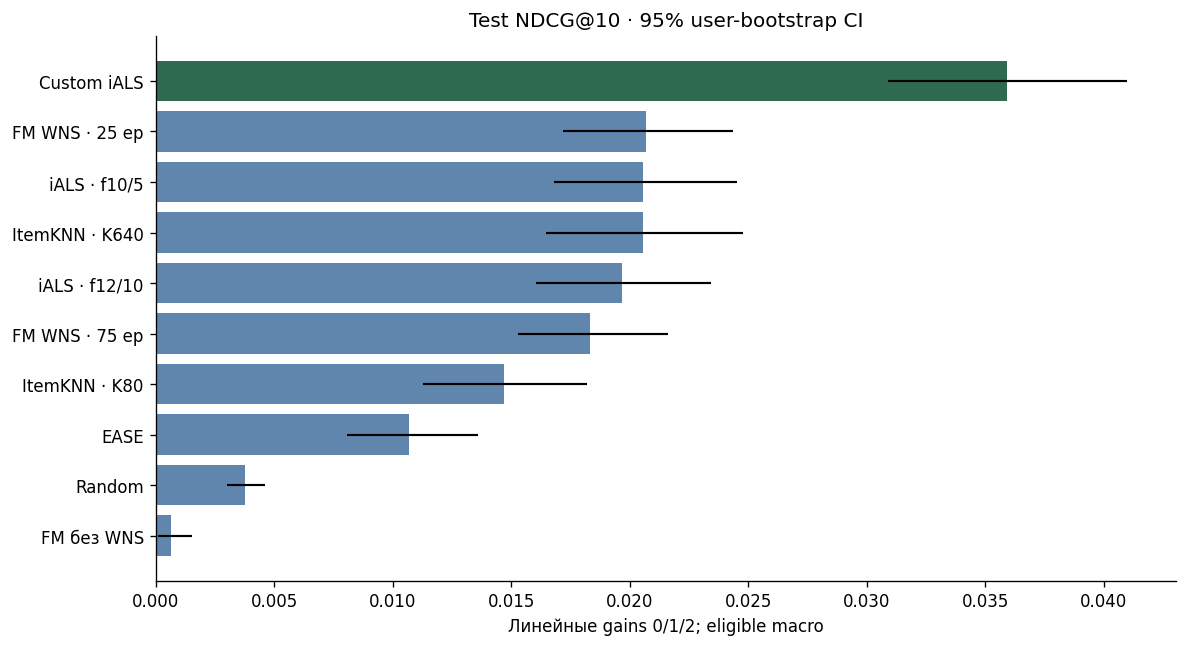

In [31]:
plot=TABLE.sort_values('ndcg_at_10')
fig,ax=plt.subplots(figsize=(10,5.5))
ax.barh(plot['Название'],plot.ndcg_at_10,color=['#2d6a4f' if x=='CIALS-TIME' else '#6086ad' for x in plot.model])
# Percentile CI не обязан содержать point estimate: рисуем границы непосредственно.
ax.hlines(np.arange(len(plot)),plot.ndcg_at_10_ci_low,plot.ndcg_at_10_ci_high,color='black',linewidth=1.3)
ax.set_title('Test NDCG@10 · 95% user-bootstrap CI')
ax.set_xlabel('Линейные gains 0/1/2; eligible macro')
plt.tight_layout();plt.show()

**Результаты эксперимента.** Custom iALS лидирует по всем трём метрикам: NDCG 0.035920, Recall 0.063081, MAP 0.021088. FM-WNS25, iALS f10 и KNN640 близки по NDCG; их порядок по точечным оценкам не доказывает различий в генеральной совокупности. FM без WNS хуже Random.

При `REPRODUCE=True` этот абзац остаётся **интерпретацией исходного эксперимента**; актуальные значения и отклонения представлены в вычисленных таблицах.

### 6.2. Validation и test: контекст, а не чистый эффект времени

Validation — неделя 25, test — 26; при test добавилась неделя обучения и изменились состав holdout и eligible-пользователи. Более того, часть архивных validation-значений относится к seed42, тогда как test — к среднему seeds. Поэтому не строим общий столбец процентного «ухудшения/улучшения переноса». Для каждой строки показываем способ validation-усреднения.

In [32]:
comparison=TABLE[['model','Название','validation_ndcg_at_10','ndcg_at_10']].merge(
 validation_view[['model','Val aggregation']],on='model',validate='one_to_one')
comparison['Test aggregation']=comparison.model.map(dict(zip(TABLE.model,TABLE.n_seeds))).map(lambda n:f'{n} run(s)')
display(comparison.drop(columns='model').round(6))

,Название,validation_ndcg_at_10,ndcg_at_10,Val aggregation,Test aggregation
0,Custom iALS,0.027401,0.035920,mean seeds 42–44,3 run(s)
1,FM WNS · 25 ep,0.019822,0.020699,mean seeds 42–44,3 run(s)
2,iALS · f10/5,0.020499,0.020563,seed 42,3 run(s)
3,ItemKNN · K640,0.018522,0.020552,deterministic,1 run(s)
4,iALS · f12/10,0.020702,0.019680,seed 42,3 run(s)
5,FM WNS · 75 ep,0.020786,0.018336,mean seeds 42–44,3 run(s)
6,ItemKNN · K80,0.018183,0.014687,deterministic,1 run(s)
7,EASE,0.014335,0.010709,deterministic,1 run(s)
8,Random,0.003595,0.003774,mean seeds 42–46,5 run(s)
9,FM без WNS,0.000733,0.000646,seed 42,3 run(s)


**Пример чувствительности к seeds.** У iALS f12 одиночная validation-оценка 0.020702 выше test-среднего 0.019680. Но validation-среднее по трём seeds около 0.018913 — уже ниже test. Поэтому фраза «модель потеряла 4.9% качества при переносе» без уточнения усреднения вводит в заблуждение. Для Custom историческое среднее выросло 0.027401 → 0.035920; это описательная разница между периодами, а не доказанный эффект дополнительной недели обучения.

### 6.3. Seeds и парные доверительные интервалы

Показываем все фиксированные seeds, без отбора лучшего. Bootstrap сначала усредняет персональные метрики по seeds, затем пересэмплирует пользователей; это неопределённость условно по обученным моделям. Семь парных контрастов заданы исходным финальным протоколом. Интервалы pointwise 95%, без коррекции за множественные сравнения.

В эксперименте Custom − iALS f12: +0.016241, CI [+0.013333; +0.019125]. Это преимущество выбранной **конфигурации**: на test одновременно различаются target и итерации (15 против 10). Контроли с одинаковыми итерациями и постоянным масштабом target выполнены на validation, использовавшейся для подбора.

In [33]:
ci=TABLE[['model','ndcg_at_10','ndcg_at_10_ci_low','ndcg_at_10_ci_high','ndcg_at_10_seed_std']].copy()
ci['model']=ci.model.map(NAME_MAP)
ci=ci.sort_values('ndcg_at_10',ascending=False)
display(ci.rename(columns={'model':'Модель','ndcg_at_10':'NDCG','ndcg_at_10_ci_low':'CI low',
                           'ndcg_at_10_ci_high':'CI high','ndcg_at_10_seed_std':'SD(seeds)'}).round(6))

print('Все фиксированные seeds:')
display(ACTIVE_RUNS[['model','seed','ndcg_at_10','recall_at_10','map_at_10']].round(6))
print('Парные контрасты (A − B):')
display(ACTIVE_PAIRED[['model_a','model_b','estimate','ci_low','ci_high']].round(6))

Все фиксированные seeds:
Парные контрасты (A − B):


,Модель,NDCG,CI low,CI high,SD(seeds)
0,Custom iALS,0.035920,0.030886,0.041004,0.001691
1,FM WNS · 25 ep,0.020699,0.017199,0.024375,0.001199
2,iALS · f10/5,0.020563,0.016820,0.024534,0.002316
3,ItemKNN · K640,0.020552,0.016459,0.024765,NaN
4,iALS · f12/10,0.019680,0.016068,0.023456,0.000601
5,FM WNS · 75 ep,0.018336,0.015290,0.021634,0.000766
6,ItemKNN · K80,0.014687,0.011265,0.018201,NaN
7,EASE,0.010709,0.008086,0.013596,NaN
8,Random,0.003774,0.003016,0.004603,0.000402
9,FM без WNS,0.000646,0.000098,0.001521,0.000228


,model,seed,ndcg_at_10,recall_at_10,map_at_10
0,KNN-80,NaN,0.014687,0.027387,0.008283
1,KNN-640,NaN,0.020552,0.037280,0.011935
2,EASE-100,NaN,0.010709,0.019971,0.005660
3,IALS-10,42.0,0.019703,0.034936,0.011426
4,IALS-10,43.0,0.018799,0.031194,0.011661
5,IALS-10,44.0,0.023186,0.041650,0.013460
6,IALS-12,42.0,0.020228,0.036073,0.011613
7,IALS-12,43.0,0.019037,0.032771,0.010760
8,IALS-12,44.0,0.019773,0.032661,0.012083
9,FM-0,42.0,0.000512,0.001101,0.000321


,model_a,model_b,estimate,ci_low,ci_high
0,CIALS-TIME,IALS-12,0.016241,0.013333,0.019125
1,FM-WNS-75,FM-0,0.017689,0.014553,0.021054
2,FM-WNS-75,FM-WNS-25,-0.002364,-0.004711,0.000107
3,KNN-640,KNN-80,0.005865,0.001624,0.010180
4,IALS-12,IALS-10,-0.000883,-0.002816,0.001120
5,CIALS-TIME,FM-WNS-75,0.017585,0.012450,0.022279
6,CIALS-TIME,RANDOM,0.032146,0.026987,0.037270


## 7. Интерпретация и ограничения

### 7.1. Custom target и свойства выдачи

В эксперименте Custom чаще находила хотя бы одно известное положительное видео: около 216 из 1817 eligible-пользователей на seed против 124 у iALS f12. Медиана длительности выдачи сместилась с 26 до 59 секунд. Это согласуется с гипотезой об абсолютном времени, но не доказывает причинного механизма или роста удовлетворённости. Более длинная выдача может быть нежелательным перекосом.

Следующая диагностика в отчётном режиме описывает архивные выдачи; в режиме воспроизведения пересчитывается по новым рекомендациям и metadata. Медианы длительности сначала считаются отдельно на seed, затем усредняются.

,Название,duration_median,over60_pct,coverage,top100_pct,hit_users_pct
0,ItemKNN · K80,19.00,13.97,1886.00,29.39,5.06
1,ItemKNN · K640,25.00,15.34,1866.00,24.37,6.82
2,EASE,12.00,3.62,1083.00,54.89,4.24
3,iALS · f10/5,24.00,13.35,1701.33,23.88,6.79
4,iALS · f12/10,25.67,14.46,1767.00,22.05,6.82
5,FM без WNS,9.00,0.81,630.00,89.91,0.15
6,FM WNS · 25 ep,15.00,7.77,1333.00,47.98,6.73
7,FM WNS · 75 ep,15.33,7.55,1335.00,46.67,6.29
8,Custom iALS,59.00,42.14,1493.33,23.88,11.89
9,Random,43.00,25.40,1999.40,8.46,1.46


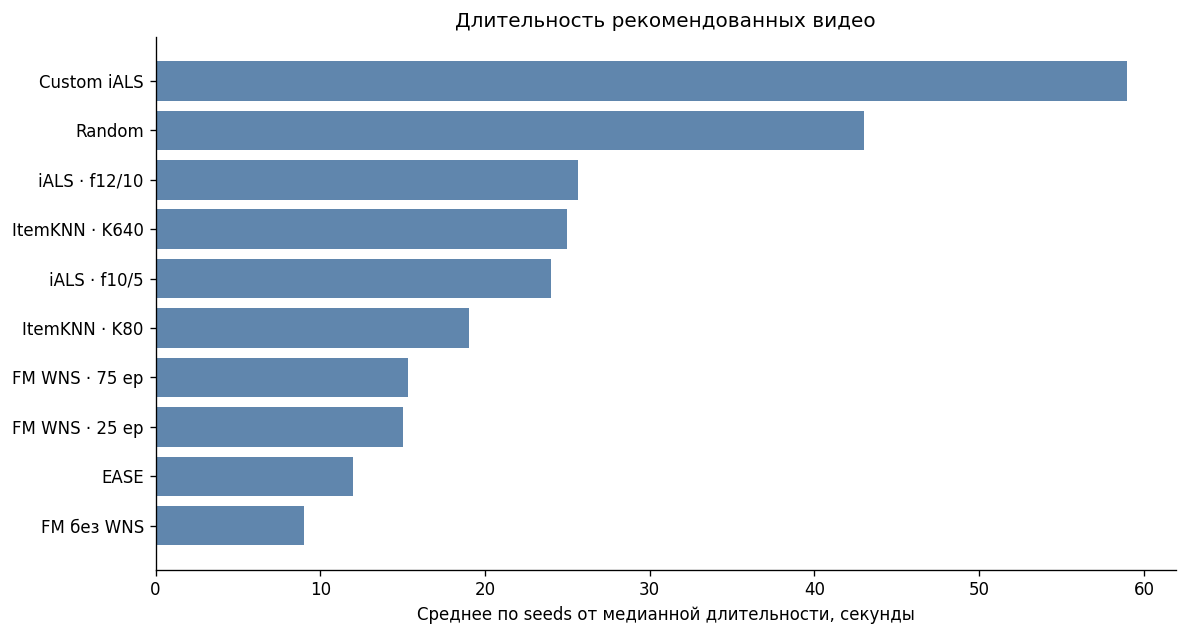

In [34]:
ARCHIVE_BIAS=pd.read_csv(StringIO('model,duration_median,over60_pct,coverage,top100_pct,users_with_hit\nKNN-80,19.0,13.973333333333333,1886.0,29.386666666666667,92.0\nKNN-640,25.0,15.343333333333334,1866.0,24.373333333333335,124.0\nEASE-100,12.0,3.62,1083.0,54.89333333333333,77.0\nIALS-10,24.0,13.346666666666666,1701.3333333333333,23.884444444444444,123.33333333333333\nIALS-12,25.666666666666668,14.463333333333333,1767.0,22.05,124.0\nFM-0,9.0,0.8066666666666666,630.0,89.91444444444444,2.6666666666666665\nFM-WNS-25,15.0,7.772222222222223,1333.0,47.98222222222222,122.33333333333333\nFM-WNS-75,15.333333333333334,7.546666666666667,1335.0,46.67444444444445,114.33333333333333\nCIALS-TIME,59.0,42.13666666666666,1493.3333333333333,23.878888888888884,216.0\nRANDOM,43.0,25.399333333333335,1999.4,8.459999999999999,26.6\n'))
BIAS=(RERUN_BIAS.copy() if REPRODUCE else ARCHIVE_BIAS.copy())
BIAS['Название']=BIAS.model.map(NAME_MAP)
BIAS['hit_users_pct']=100*BIAS.users_with_hit/1817
display(BIAS[['Название','duration_median','over60_pct','coverage','top100_pct','hit_users_pct']].round(2))
fig,ax=plt.subplots(figsize=(10,5.4))
b=BIAS.sort_values('duration_median')
ax.barh(b['Название'],b.duration_median,color='#6086ad')
ax.set_title('Длительность рекомендованных видео');ax.set_xlabel('Среднее по seeds от медианной длительности, секунды')
plt.tight_layout();plt.show()

### 7.2. Что можно и нельзя заключить

- **Абсолютное качество.** NDCG 0.035920 не является «3.6% правильных видео». В test в среднем 2.08 известных позитивов на eligible-пользователя среди большого непросмотренного каталога. Custom превосходит Random примерно в 9.52 раза по NDCG, но у 88.1% eligible-пользователей на один seed нет ни одного наблюдаемого попадания. Это содержательный учебный результат, не доказательство высокого онлайн-качества.
- **WNS.** Рост 0.000646 → 0.020699 (32.02×; абсолютная Δ≈0.020053) относится к разным режимам и бюджетам обучения одной FM, а не к новой архитектуре. Для WNS75−WNS25 paired CI [−0.004711; +0.000107] включает ноль; ухудшение 75 эпох по точечной оценке не универсальный закон.
- **Разнообразие.** Custom улучшает точность, но покрывает меньше видео, чем KNN640 или iALS f12. Рост по NDCG не означает улучшения всех свойств рекомендаций.
- **Неполные оценки.** Неэкспонированные пары получают нулевой evaluation gain; это не истинные дизлайки. Offline-логи смещены политикой показов. Пользовательский bootstrap этого не исправляет.
- **Выборка.** Каталог фиксирован по train: новые IDs исключены, cold start не проверялся. Test сохраняет 3.47% событий исходной недели. Матрица train имеет плотность 24.24%, поэтому низкую метрику нельзя объяснять только «огромным разреженным train».
- **Неопределённость.** Одна test-неделя, три seeds для обучаемых стохастических методов, многочисленные validation-попытки. Интервалы не охватывают всю неопределённость выбора модели и будущих недель.
- **Metadata.** Код не агрегирует test-feedback, но время формирования исходного snapshot, особенно `geo`, не подтверждено.
- **Контроли.** Random — слабый baseline; превосходство над ним не доказывает превосходства над всеми простыми временными или популярностными методами. Новые методы после открытия test нельзя незаметно включать в первоначальный протокол.

## 8. Выводы и запуск

Custom iALS показала лучшие NDCG@10, Recall@10 и MAP@10. Контрольные сравнения
на validation поддерживают полезность непрерывного целевого сигнала;
разница на test отражает также различия числа итераций. Для FM обучение
с дополнительными неизвестными парами улучшило результат. Убедительная
польза метаданных в проведённой абляции не обнаружена.

Для просмотра выполните все ячейки с `REPRODUCE=False`. Для повторного обучения
установите `REPRODUCE=True`. Зависимости устанавливаются командой
`python -m pip install -r requirements.txt`.

Данные и код подбора можно запустить из терминала, находясь в корне проекта:

```bash
python -m models.prepare_data
python -m models.experiments.eda
python -m models.experiments.eda_followup
python -m models.experiments.eda_checks
python -m models.experiments.relevance
python -m models.experiments.relevance_duration
python -m models.experiments.baselines
python -m models.experiments.item_knn
python -m models.experiments.ials
python -m models.experiments.ials_lowrank
python -m models.experiments.ease
python -m models.experiments.fm
python -m models.experiments.fm_epochs
python -m models.experiments.fm_wns
python -m models.experiments.fm_wns_beta
python -m models.experiments.fm_wns_beta_large
python -m models.experiments.fm_wns_epochs
python -m models.experiments.fm_ablation
python -m models.experiments.custom_ials
python -m models.experiments.custom_controls
python -m models.experiments.custom_time
```

Скрипты расширения используют результаты предыдущих этапов; выполнять их
следует в указанном порядке. Сетки требуют существенно больше времени,
чем просмотр отчёта. Промежуточные результаты и checkpoints создаются
в `results/`. После подбора финальные настройки сравниваются в §5–6.
